# Toxic Comment Classification Using Deep Learning

**AIP301 Hands-on Assignment**

This notebook builds a deep learning model that classifies online comments into toxicity categories.
It is organised under the five assignment tasks:

1. Dataset Loading and Initial Exploration
2. Text Cleaning, Preprocessing, Data Quality, and Target Analysis
3. NLP Tokenization and Sequence Padding
4. Deep Learning Model Development, Training, and Validation
5. Model Evaluation, Visualization, and Prediction

---
## Task 1: Dataset Loading and Initial Exploration

Before cleaning text or building a model, we need to understand the data: what each record looks like,
how many records and columns there are, what type each column has, and whether there are missing or
duplicate values.

### 1.1 Import libraries

- **pandas** loads and explores tabular data (a `DataFrame` is like a spreadsheet in Python).
- **numpy** provides fast numerical arrays.
- **pathlib.Path** builds file paths that work on Windows, macOS, and Linux.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

# Show all columns and longer text when displaying DataFrames
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

print("pandas version:", pd.__version__)
print("numpy version :", np.__version__)

pandas version: 3.0.6
numpy version : 2.5.3


### 1.2 Locate the project folders

The notebook lives in `notebooks/`, while the dataset lives in `data/`.
This cell finds the project root so the notebook works whether Jupyter is started
from the project root or from the `notebooks/` folder.

In [2]:
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "toxic_comments_dataset.csv"

print("Project root:", PROJECT_ROOT.resolve())
print("Dataset path:", DATA_PATH.resolve())
print("Dataset found:", DATA_PATH.exists())

Project root: D:\CProjects\toxic-comment-classification-dl
Dataset path: D:\CProjects\toxic-comment-classification-dl\data\toxic_comments_dataset.csv
Dataset found: True


### 1.3 Load the dataset

`pd.read_csv()` reads the CSV file into a DataFrame. Each row is one comment,
and each column is one attribute of that comment.

In [3]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. "
        "Place toxic_comments_dataset.csv inside the data/ folder."
    )

df = pd.read_csv(DATA_PATH)
print("Dataset loaded successfully.")

Dataset loaded successfully.


### 1.4 Display the first 10 records

`df.head(10)` shows the first 10 rows so we can see what real records look like.

In [4]:
df.head(10)

,Comment_ID,Comment_Text,Toxicity_Label,Clean,Toxic,Severe_Toxic,Threat,Identity_Attack,Toxicity_Score,Comment_Length,Word_Count,Platform,Topic,Moderation_Priority,Language
0,COM000001,"In this discussion, the message expresses a clear opinion about the subject. Source wording: Comment for review: ""Th...",Identity_Attack,0,1,0,0,1,0.818,66,10,Community Chat,Sports,High,English
1,COM000002,"Regarding the point raised, the message expresses a clear opinion about the subject. Source wording: Comment for rev...",Clean,1,0,0,0,0,0.069,58,9,News Comments,Entertainment,High,English
2,COM000003,"From the information provided, the message expresses a clear opinion about the subject. Source wording: Comment for ...",Toxic,0,1,0,0,0,0.622,44,7,Social Media,Politics,Low,English
3,COM000004,"In the current conversation, the message expresses a clear opinion about the subject. Source wording: Comment for re...",Clean,1,0,0,0,0,0.010,61,9,Social Media,Entertainment,Low,English
4,COM000005,"Looking at this issue, the message expresses a clear opinion about the subject. Source wording: Comment for review: ...",Clean,1,0,0,0,0,0.140,52,8,Blog,Sports,Low,English
5,COM000006,"For this particular topic, the message expresses a clear opinion about the subject. Source wording: Comment for revi...",Toxic,0,1,0,0,0,0.729,44,7,Social Media,Technology,Low,English
6,COM000007,"In response to the statement, the message expresses a clear opinion about the subject. Source wording: Comment for r...",Clean,1,0,0,0,0,0.193,52,8,Blog,Entertainment,Low,English
7,COM000008,"Considering the context, the message expresses a clear opinion about the subject. Source wording: Comment for review...",Clean,1,0,0,0,0,0.183,61,9,Forum,Gaming,Low,English
8,COM000009,"On this subject, the message expresses a clear opinion about the subject. Source wording: Comment for review: ""This ...",Clean,1,0,0,0,0,0.142,60,8,Social Media,Education,Medium,English
9,COM000010,"With respect to the comment, the message expresses a clear opinion about the subject. Source wording: Comment for re...",Clean,1,0,0,0,0,0.153,61,9,Forum,Entertainment,Low,English


### 1.5 Display the last 8 records

`df.tail(8)` shows the last 8 rows. Checking the end of the file confirms the whole file
was read correctly (for example, no broken rows at the end).

In [5]:
df.tail(8)

,Comment_ID,Comment_Text,Toxicity_Label,Clean,Toxic,Severe_Toxic,Threat,Identity_Attack,Toxicity_Score,Comment_Length,Word_Count,Platform,Topic,Moderation_Priority,Language
29992,COM029993,"Considering the context, the statement addresses a response to the preceding point. Source wording: Comment for revi...",Toxic,0,1,0,0,0,0.520,52,7,Forum,Gaming,Medium,English
29993,COM029994,"On this subject, the statement addresses a response to the preceding point. Source wording: Comment for review: ""I a...",Clean,1,0,0,0,0,0.195,61,9,News Comments,Sports,Medium,English
29994,COM029995,"With respect to the comment, the statement addresses a response to the preceding point. Source wording: Comment for ...",Clean,1,0,0,0,0,0.174,58,9,Community Chat,Gaming,Low,English
29995,COM029996,"In reviewing this exchange, the statement addresses a response to the preceding point. Source wording: Comment for r...",Clean,1,0,0,0,0,0.013,60,8,Community Chat,Sports,Medium,English
29996,COM029997,"For the matter being discussed, the statement addresses a response to the preceding point. Source wording: Comment f...",Clean,1,0,0,0,0,0.050,52,8,Blog,Politics,Medium,English
29997,COM029998,"Based on the message, the statement addresses a response to the preceding point. Source wording: Comment for review:...",Clean,1,0,0,0,0,0.078,61,9,Forum,Sports,Low,English
29998,COM029999,"In the wider discussion, the statement addresses a response to the preceding point. Source wording: Comment for revi...",Clean,1,0,0,0,0,0.003,60,8,Social Media,Sports,Medium,English
29999,COM030000,"As part of this conversation, the statement addresses a response to the preceding point. Source wording: Comment for...",Clean,1,0,0,0,0,0.082,61,9,Community Chat,Education,High,English


### 1.6 Dataset dimensions

`df.shape` returns a tuple `(number_of_rows, number_of_columns)`.

In [6]:
n_rows, n_cols = df.shape
print(f"Number of rows (comments): {n_rows:,}")
print(f"Number of columns        : {n_cols}")

Number of rows (comments): 30,000
Number of columns        : 15


### 1.7 Column names

`df.columns` lists every column name. We use these real names later to choose the
text column and the target column (we do not assume them).

In [7]:
for i, col in enumerate(df.columns, start=1):
    print(f"{i:2d}. {col}")

 1. Comment_ID
 2. Comment_Text
 3. Toxicity_Label
 4. Clean
 5. Toxic
 6. Severe_Toxic
 7. Threat
 8. Identity_Attack
 9. Toxicity_Score
10. Comment_Length
11. Word_Count
12. Platform
13. Topic
14. Moderation_Priority
15. Language


### 1.8 Data types

`df.dtypes` shows the type of each column:

- **int64** – whole numbers (for example 0/1 label flags or word counts)
- **float64** – decimal numbers (for example a toxicity score)
- **object / str** – text

`df.info()` also shows the number of non-null values per column and the memory usage.

In [8]:
df.dtypes.to_frame(name="dtype")

,dtype
Comment_ID,str
Comment_Text,str
Toxicity_Label,str
Clean,int64
Toxic,int64
Severe_Toxic,int64
Threat,int64
Identity_Attack,int64
Toxicity_Score,float64
Comment_Length,int64


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Comment_ID           30000 non-null  str    
 1   Comment_Text         30000 non-null  str    
 2   Toxicity_Label       30000 non-null  str    
 3   Clean                30000 non-null  int64  
 4   Toxic                30000 non-null  int64  
 5   Severe_Toxic         30000 non-null  int64  
 6   Threat               30000 non-null  int64  
 7   Identity_Attack      30000 non-null  int64  
 8   Toxicity_Score       30000 non-null  float64
 9   Comment_Length       30000 non-null  int64  
 10  Word_Count           30000 non-null  int64  
 11  Platform             30000 non-null  str    
 12  Topic                30000 non-null  str    
 13  Moderation_Priority  30000 non-null  str    
 14  Language             30000 non-null  str    
dtypes: float64(1), int64(7), str(7)
memory usage: 3

### 1.9 Statistical summary of numerical columns

`df.describe()` calculates, for each numerical column, the count, mean, standard deviation,
minimum, quartiles (25%, 50% = median, 75%), and maximum.

For the 0/1 label columns, the **mean** is the proportion of comments that have that label.

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Clean,30000.0,0.619300,0.485567,0.0,0.000,1.000,1.000,1.00
Toxic,30000.0,0.380700,0.485567,0.0,0.000,0.000,1.000,1.00
Severe_Toxic,30000.0,0.060033,0.237553,0.0,0.000,0.000,0.000,1.00
Threat,30000.0,0.048633,0.215104,0.0,0.000,0.000,0.000,1.00
Identity_Attack,30000.0,0.048933,0.215732,0.0,0.000,0.000,0.000,1.00
Toxicity_Score,30000.0,0.324542,0.302914,0.0,0.079,0.161,0.624,0.95
Comment_Length,30000.0,56.357633,6.962596,39.0,52.000,58.000,61.000,71.00
Word_Count,30000.0,8.340633,0.972094,6.0,8.000,8.000,9.000,11.00


### 1.10 Missing values

`df.isnull().sum()` counts empty values in each column. Missing comment text or missing labels
would have to be handled before training.

In [11]:
missing = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percent": (df.isnull().mean() * 100).round(2),
})
print("Total missing values in the dataset:", int(missing["missing_count"].sum()))
missing

Total missing values in the dataset: 0


,missing_count,missing_percent
Comment_ID,0,0.0
Comment_Text,0,0.0
Toxicity_Label,0,0.0
Clean,0,0.0
Toxic,0,0.0
Severe_Toxic,0,0.0
Threat,0,0.0
Identity_Attack,0,0.0
Toxicity_Score,0,0.0
Comment_Length,0,0.0


### 1.11 Duplicate records

We check duplicates at three levels:

1. **Fully duplicated rows** – every column is identical.
2. **Duplicated `Comment_ID` values** – IDs should be unique.
3. **Duplicated `Comment_Text` values** – the same comment text appearing more than once
   (this matters for NLP because repeated text can leak between training and test sets).

In [12]:
duplicate_summary = pd.Series({
    "Fully duplicated rows": df.duplicated().sum(),
    "Duplicated Comment_ID values": df["Comment_ID"].duplicated().sum(),
    "Duplicated Comment_Text values": df["Comment_Text"].duplicated().sum(),
}, name="count")
duplicate_summary.to_frame()

,count
Fully duplicated rows,0
Duplicated Comment_ID values,0
Duplicated Comment_Text values,0


### 1.12 Quick look at the text and categorical columns

To prepare for the next task, we check how many unique values each text/categorical column has.
A column with very few unique values (such as a label) is categorical; a column where almost
every value is unique (such as the comment text) is free text.

In [13]:
text_columns = df.select_dtypes(exclude="number").columns
df[text_columns].nunique().to_frame(name="unique_values")

,unique_values
Comment_ID,30000
Comment_Text,30000
Toxicity_Label,5
Platform,5
Topic,6
Moderation_Priority,3
Language,1


### Task 1 Summary

The outputs above show:

- the dataset's real size and its 15 columns;
- **`Comment_Text`** is the free-text column we will use as model input;
- **`Toxicity_Label`** is a single categorical column, and the binary columns `Clean`, `Toxic`,
  `Severe_Toxic`, `Threat`, and `Identity_Attack` hold 0/1 label flags; both are analysed in Task 2;
- the missing-value and duplicate counts, which tell us how much cleaning is needed.

Next, Task 2 cleans the comment text and analyses the target labels.

---
## Task 2: Text Cleaning, Preprocessing, Data Quality, and Target Analysis

Raw text contains things that do not help a model learn (capital letters, punctuation, numbers,
HTML, links, emojis). In this task we:

1. clean the comment text with a reusable function,
2. check missing values and duplicates,
3. analyse the target labels and choose the target for the model.

### 2.1 Import the reusable cleaning function and plotting libraries

The cleaning function lives in `src/preprocessing.py`, not inside the notebook. That way the
**exact same function** is reused later by `src/predict.py` when classifying new comments.
If training text and new text were cleaned differently, the model would see unfamiliar input.

In [14]:
import sys

import matplotlib.pyplot as plt
import seaborn as sns

if str(PROJECT_ROOT.resolve()) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT.resolve()))

from src.preprocessing import clean_text

PLOTS_DIR = PROJECT_ROOT / "outputs" / "plots"
REPORTS_DIR = PROJECT_ROOT / "outputs" / "reports"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="white")
print("clean_text imported from src/preprocessing.py")

clean_text imported from src/preprocessing.py


### 2.2 How the cleaning function works

`clean_text()` applies these steps in order:

| Step | What it does | Example |
|---|---|---|
| 1 | Missing value → empty string | `NaN` → `""` |
| 2 | Lowercase | `HELLO` → `hello` |
| 3 | Decode HTML entities and remove HTML tags | `<b>hi</b> &amp;` → `hi &` |
| 4 | Remove URLs and e-mail addresses | `see https://x.com` → `see` |
| 5 | Remove apostrophes (keep contractions as one word) | `don't` → `dont` |
| 6 | Remove punctuation, digits, special characters, emojis | `wow!!! 123 😡` → `wow` |
| 7 | Collapse extra whitespace | `a    b` → `a b` |

The dataset does not contain every kind of noise, so the cell below first tests the function
on a few **hand-written demonstration strings** (these are not from the dataset).

In [15]:
demo_comments = [
    "<p>This is <b>GREAT</b> work &amp; very helpful!</p>",
    "Check https://example.com/page?id=7 and www.example.org NOW!!!",
    "You're SO annoying 😡😡 #angry @user123",
    "Call 555-0199 before 10:30pm...   thanks",
    None,
]
pd.DataFrame({
    "original": demo_comments,
    "cleaned": [clean_text(c) for c in demo_comments],
})

,original,cleaned
0,<p>This is <b>GREAT</b> work &amp; very helpful!</p>,this is great work very helpful
1,Check https://example.com/page?id=7 and www.example.org NOW!!!,check and now
2,You're SO annoying 😡😡 #angry @user123,youre so annoying angry user
3,Call 555-0199 before 10:30pm... thanks,call before pm thanks
4,NaN,


### 2.3 Handle missing comment text

Task 1 showed no missing values. We still handle them explicitly so the code is safe for other
data: missing text becomes an empty string inside `clean_text()`, and any row whose cleaned text
is empty is removed, because an empty comment gives the model nothing to learn from.

In [16]:
print("Missing Comment_Text values:", df["Comment_Text"].isnull().sum())

df["clean_text"] = df["Comment_Text"].apply(clean_text)

empty_mask = df["clean_text"].str.len() == 0
print("Rows with empty text after cleaning:", int(empty_mask.sum()))

df = df.loc[~empty_mask].reset_index(drop=True)
print("Rows remaining:", len(df))

Missing Comment_Text values: 0


Rows with empty text after cleaning: 0
Rows remaining: 30000


### 2.4 Before-and-after cleaning examples from the dataset

The table compares original and cleaned text for real records. The third example contains a
number (`entry reference ...`), which shows digits and brackets being removed.

In [17]:
digit_example = df.index[df["Comment_Text"].str.contains(r"\d", regex=True)][0]
example_rows = [0, 1, digit_example, 3, 4]

for i in example_rows:
    print(f"[Row {i}] Label: {df.at[i, 'Toxicity_Label']}")
    print("  BEFORE:", df.at[i, "Comment_Text"])
    print("  AFTER :", df.at[i, "clean_text"])
    print()

[Row 0] Label: Identity_Attack
  BEFORE: In this discussion, the message expresses a clear opinion about the subject. Source wording: Comment for review: "The message targets a group unfairly and violates community rules.". and the surrounding context should guide its interpretation.
  AFTER : in this discussion the message expresses a clear opinion about the subject source wording comment for review the message targets a group unfairly and violates community rules and the surrounding context should guide its interpretation

[Row 1] Label: Clean
  BEFORE: Regarding the point raised, the message expresses a clear opinion about the subject. Source wording: Comment for review: "Thank you for sharing this perspective with the community.". and the surrounding context should guide its interpretation.
  AFTER : regarding the point raised the message expresses a clear opinion about the subject source wording comment for review thank you for sharing this perspective with the community and the s

In [18]:
before_words = df["Comment_Text"].str.split().str.len()
after_words = df["clean_text"].str.split().str.len()
pd.DataFrame({"before cleaning": before_words.describe(), "after cleaning": after_words.describe()}).round(1).T

,count,mean,std,min,25%,50%,75%,max
before cleaning,30000.0,37.0,2.0,30.0,36.0,37.0,38.0,46.0
after cleaning,30000.0,37.0,2.1,30.0,36.0,37.0,38.0,46.0


### 2.5 Duplicate comments and conflicting labels

Duplicates matter because:

- an exact duplicate adds no new information, and
- if one copy lands in the training set and another in the test set, the test score looks
  better than it really is (**data leakage**).

Cleaning can create new duplicates (for example, two texts that differed only in punctuation),
so we check duplicates **after** cleaning too. For each duplicated text we also check whether
its copies have **different labels**. Conflicting labels are reported, not silently dropped,
because deciding which label is correct needs a human.

In [19]:
dup_raw = df["Comment_Text"].duplicated().sum()
dup_clean = df["clean_text"].duplicated().sum()
print("Duplicate raw comments    :", dup_raw)
print("Duplicate cleaned comments:", dup_clean)

labels_per_text = df.groupby("clean_text")["Toxicity_Label"].nunique()
conflicting_texts = labels_per_text[labels_per_text > 1]
print("Cleaned texts with conflicting labels:", len(conflicting_texts))

if len(conflicting_texts) > 0:
    conflicts = df[df["clean_text"].isin(conflicting_texts.index)].sort_values("clean_text")
    conflicts.to_csv(REPORTS_DIR / "conflicting_label_duplicates.csv", index=False)
    print("Conflicting rows saved to outputs/reports/conflicting_label_duplicates.csv")
    display(conflicts[["Comment_ID", "clean_text", "Toxicity_Label"]].head(20))

Duplicate raw comments    : 0
Duplicate cleaned comments: 0
Cleaned texts with conflicting labels: 0


In [20]:
# Keep only the first copy of exact duplicates whose labels agree.
# Conflicting duplicates (if any) were reported above and are kept for manual review.
consistent_dup_mask = df["clean_text"].duplicated(keep="first") & ~df["clean_text"].isin(conflicting_texts.index)
print("Consistent duplicates removed:", int(consistent_dup_mask.sum()))
df = df.loc[~consistent_dup_mask].reset_index(drop=True)
print("Rows remaining:", len(df))

Consistent duplicates removed: 0
Rows remaining: 30000


### 2.6 Near-duplicates: the core comment inside each record

Every text in this dataset follows the same pattern: an introductory phrase, then
`Source wording: Comment for review: "..."`, then a closing phrase. The part in quotes is the
**core comment**. Its length matches the `Comment_Length` column exactly.

So although no two full texts are identical, many records may share the same core comment
wrapped in different phrases. The cell below extracts the core comment and counts how many
distinct core comments exist and how consistently each one is labelled.

In [21]:
df["core_comment"] = df["Comment_Text"].str.extract(r'Comment for review: "(.*?)"\.', expand=False)

print("Records where a core comment was found:", df["core_comment"].notna().sum(), "of", len(df))
print("Core comment length equals Comment_Length:", bool((df["core_comment"].str.len() == df["Comment_Length"]).all()))
print("Distinct core comments:", df["core_comment"].nunique())

core_labels = df.groupby("core_comment")["Toxicity_Label"].nunique()
print("Core comments with more than one label:", int((core_labels > 1).sum()))

core_table = (
    df.groupby(["Toxicity_Label", "core_comment"]).size()
    .rename("records").reset_index()
    .sort_values(["Toxicity_Label", "records"], ascending=[True, False])
)
core_table.to_csv(REPORTS_DIR / "core_comment_summary.csv", index=False)
core_table

Records where a core comment was found: 30000 of 30000
Core comment length equals Comment_Length: True
Distinct core comments: 17
Core comments with more than one label: 0


,Toxicity_Label,core_comment,records
3,Clean,This article provides useful information and clear examples.,4685
2,Clean,Thank you for sharing this perspective with the community.,4681
1,Clean,I respectfully disagree but I understand your point.,4659
0,Clean,I appreciate your explanation and the discussion was helpful.,4554
5,Identity_Attack,This comment attacks someone based on identity and should be moderated.,493
4,Identity_Attack,The message targets a group unfairly and violates community rules.,488
6,Identity_Attack,This reply includes discriminatory language and needs review.,487
8,Severe_Toxic,This message contains severe abusive language and should be removed.,620
7,Severe_Toxic,The comment is extremely hostile and violates community standards.,593
9,Severe_Toxic,This reply includes intense personal abuse and harmful wording.,588


**What this means for the project**

- The dataset is built from a small number of distinct core comments, and each core comment
  always carries the same label, so there are no label conflicts.
- The surrounding phrases vary, so these are **near-duplicates**, not exact duplicates. We keep
  them: removing them would leave too few records to train an LSTM.
- Because a random train/test split puts the same core comments in both sets, a high test
  accuracy will mostly show that the model recognises these known comments. It does **not**
  prove the model can classify genuinely new comments. We keep this limitation in mind when we
  interpret the evaluation results in Task 5 and test the model on new comments.

### 2.7 Missing and invalid target values

The target column must contain a valid class for every record. We check for missing labels
and list the distinct label values.

In [22]:
print("Missing Toxicity_Label values:", df["Toxicity_Label"].isnull().sum())
print("Distinct labels:", sorted(df["Toxicity_Label"].unique()))

# Rows without a label cannot be used for supervised training
df = df.dropna(subset=["Toxicity_Label"]).reset_index(drop=True)
print("Rows remaining:", len(df))

Missing Toxicity_Label values: 0
Distinct labels: ['Clean', 'Identity_Attack', 'Severe_Toxic', 'Threat', 'Toxic']
Rows remaining: 30000


### 2.8 Multi-class vs multi-label: choosing the target

The dataset describes toxicity in two ways:

- **`Toxicity_Label`**: one category per comment (`Clean`, `Toxic`, `Severe_Toxic`, `Threat`,
  `Identity_Attack`). This is a **multi-class** target: each comment belongs to exactly one class.
- **Binary columns** (`Clean`, `Toxic`, `Severe_Toxic`, `Threat`, `Identity_Attack`): several can be
  1 at the same time (for example a threat is also toxic). This is a **multi-label** format, which
  would need one Sigmoid output per label and binary cross-entropy loss.

The assignment requires a **Softmax** output, which assumes the classes are **mutually exclusive**
(the predicted probabilities add up to 1). So we use `Toxicity_Label` as the target. The cells
below check that it agrees with the binary columns.

In [23]:
binary_cols = ["Clean", "Toxic", "Severe_Toxic", "Threat", "Identity_Attack"]

print("Rows with more than one binary flag set:", int((df[binary_cols].sum(axis=1) > 1).sum()))
print()
print("Average value of each binary flag, per Toxicity_Label:")
df.groupby("Toxicity_Label")[binary_cols].mean()

Rows with more than one binary flag set: 4728

Average value of each binary flag, per Toxicity_Label:


,Clean,Toxic,Severe_Toxic,Threat,Identity_Attack
Toxicity_Label,,,,,
Clean,1.0,0.0,0.0,0.0,0.0
Identity_Attack,0.0,1.0,0.0,0.0,1.0
Severe_Toxic,0.0,1.0,1.0,0.0,0.0
Threat,0.0,1.0,0.0,1.0,0.0
Toxic,0.0,1.0,0.0,0.0,0.0


The table shows a clear rule: `Toxic` is a general flag set for **every** toxic comment, and the
most specific flag decides the category. The cell below rebuilds a single label from the binary
columns using this rule and compares it with `Toxicity_Label`:

1. `Clean = 1` → **Clean**
2. otherwise `Severe_Toxic = 1` → **Severe_Toxic**
3. otherwise `Threat = 1` → **Threat**
4. otherwise `Identity_Attack = 1` → **Identity_Attack**
5. otherwise → **Toxic**

In [24]:
def derive_label(row):
    if row["Clean"] == 1:
        return "Clean"
    for label in ["Severe_Toxic", "Threat", "Identity_Attack"]:
        if row[label] == 1:
            return label
    return "Toxic"

derived = df[binary_cols].apply(derive_label, axis=1)
agreement = (derived == df["Toxicity_Label"]).mean() * 100
print(f"Derived label matches Toxicity_Label for {agreement:.2f}% of records")

Derived label matches Toxicity_Label for 100.00% of records


### 2.9 Target label distribution

We count how many comments belong to each class, both as numbers and as percentages, and show
them in a bar chart. The chart is saved to `outputs/plots/target_distribution.png`.

In [25]:
label_counts = df["Toxicity_Label"].value_counts()
label_dist = pd.DataFrame({
    "count": label_counts,
    "percent": (label_counts / len(df) * 100).round(2),
})
label_dist.to_csv(REPORTS_DIR / "target_distribution.csv")
label_dist

,count,percent
Toxicity_Label,,
Clean,18579,61.93
Toxic,6693,22.31
Severe_Toxic,1801,6.00
Identity_Attack,1468,4.89
Threat,1459,4.86


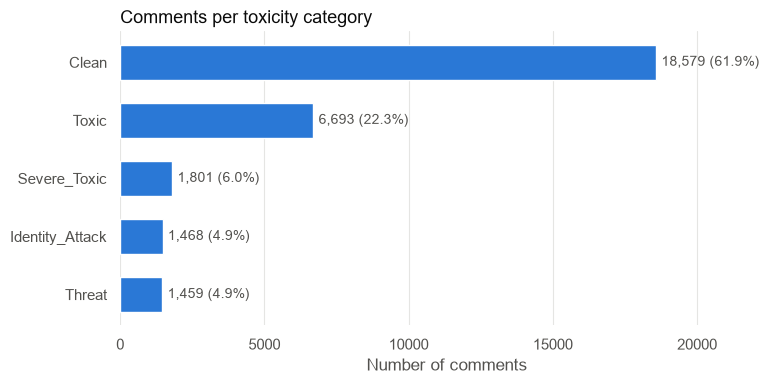

Saved to outputs/plots/target_distribution.png


In [26]:
fig, ax = plt.subplots(figsize=(8, 4))
order = label_counts.sort_values().index  # largest bar at the top
bars = ax.barh(order, label_counts[order], color="#2a78d6", height=0.6)

for bar, label in zip(bars, order):
    ax.text(
        bar.get_width() + label_counts.max() * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{label_counts[label]:,} ({label_dist.at[label, 'percent']:.1f}%)",
        va="center", fontsize=10, color="#52514e",
    )

ax.set_title("Comments per toxicity category", loc="left", fontsize=13, color="#0b0b0b")
ax.set_xlabel("Number of comments", color="#52514e")
ax.set_xlim(0, label_counts.max() * 1.22)
ax.tick_params(colors="#52514e")
ax.grid(axis="x", color="#e5e5e3", linewidth=0.8)
ax.set_axisbelow(True)
sns.despine(left=True, bottom=True)

plt.tight_layout()
fig.savefig(PLOTS_DIR / "target_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved to outputs/plots/target_distribution.png")

In [27]:
imbalance_ratio = label_counts.max() / label_counts.min()
print(f"Largest class : {label_counts.idxmax()} ({label_counts.max():,})")
print(f"Smallest class: {label_counts.idxmin()} ({label_counts.min():,})")
print(f"Imbalance ratio (largest / smallest): {imbalance_ratio:.1f}")

Largest class : Clean (18,579)
Smallest class: Threat (1,459)
Imbalance ratio (largest / smallest): 12.7


**Class imbalance.** The classes are not equally common, as the ratio above shows. A model can
reach a fairly high accuracy just by predicting the majority class most of the time, so in Task 5
we look beyond accuracy, at **per-class precision, recall, and F1-score** and the confusion matrix.
We use a **stratified** train/test split so every class keeps the same proportion in both sets.

### 2.10 Target encoding strategy

Neural networks work with numbers, not text labels, so the five class names will be turned into
integers. The encoding itself is done in the next task, **after** the train/test split. The plan:

- **Encoder:** scikit-learn `LabelEncoder`, which assigns integers in alphabetical order of the
  class names (for example `Clean → 0`). The encoder is saved so predictions can be turned back
  into class names.
- **Format:** one integer per comment (**not** one-hot vectors), so the matching loss function is
  **`sparse_categorical_crossentropy`**.
- **Output layer:** `Dense(5, activation="softmax")`, one probability per class; the predicted
  class is the one with the highest probability.

### 2.11 Final dataset for modelling

We keep only the columns needed for the next tasks: the ID, the cleaned text (model input), and
the target label.

In [28]:
model_df = df[["Comment_ID", "clean_text", "Toxicity_Label"]].copy()
print("Modelling dataset shape:", model_df.shape)
model_df.head()

Modelling dataset shape: (30000, 3)


,Comment_ID,clean_text,Toxicity_Label
0,COM000001,in this discussion the message expresses a clear opinion about the subject source wording comment for review the mes...,Identity_Attack
1,COM000002,regarding the point raised the message expresses a clear opinion about the subject source wording comment for review...,Clean
2,COM000003,from the information provided the message expresses a clear opinion about the subject source wording comment for rev...,Toxic
3,COM000004,in the current conversation the message expresses a clear opinion about the subject source wording comment for revie...,Clean
4,COM000005,looking at this issue the message expresses a clear opinion about the subject source wording comment for review i re...,Clean


### Task 2 Summary

- The text was cleaned with a reusable, tested function (`src/preprocessing.py`).
- Missing values, empty texts, exact duplicates, and label conflicts were checked, with the counts
  shown in the outputs above.
- The records are built from a small set of distinct core comments (near-duplicates). We keep them
  and treat this as a known limitation when interpreting the test results.
- `Toxicity_Label` is used as the mutually exclusive, multi-class target for the Softmax model, and
  it agrees with the binary label columns.
- The class distribution was saved to `outputs/plots/target_distribution.png` and
  `outputs/reports/target_distribution.csv`.

Next, Task 3 splits the data, encodes the labels, and converts the text into padded sequences.

---
## Task 3: NLP Tokenization and Sequence Padding

A neural network cannot read words. In this task we turn each cleaned comment into a fixed-length
list of numbers:

1. split the data into a **training set** (80%) and a **test set** (20%),
2. encode the class names as integers,
3. build a vocabulary (**tokenizer**) from the training text only,
4. replace each word with its number (**sequences**),
5. make every sequence the same length (**padding and truncation**).

### 3.1 Import libraries and set a random seed

- `train_test_split` (scikit-learn) splits the data.
- `LabelEncoder` (scikit-learn) turns class names into integers.
- `Tokenizer` and `pad_sequences` come from **`tf_keras`**, the classic Keras 2 API. Keras 3
  (bundled with current TensorFlow) removed the `Tokenizer` class, so we use the `tf_keras` package.

A fixed **random seed** makes the split and later training repeatable.

In [29]:
import os
import random

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # hide TensorFlow's low-level info messages

import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tf_keras.preprocessing.sequence import pad_sequences
from tf_keras.preprocessing.text import Tokenizer

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


### 3.2 Split into training and test sets (80/20, stratified)

- **Training set (80%)**: used to learn the vocabulary and train the model. A validation part is
  taken from it later, during training.
- **Test set (20%)**: kept aside and used **only once**, for the final evaluation. It is never
  used to build the vocabulary, train, or choose settings, so the evaluation stays fair.
- **`stratify=y`** keeps the class percentages the same in both sets. This matters here because
  some classes are small (about 5%).

In [30]:
X = model_df["clean_text"]
y = model_df["Toxicity_Label"]

X_train_text, X_test_text, y_train_labels, y_test_labels = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

print(f"Training set: {len(X_train_text):,} comments")
print(f"Test set    : {len(X_test_text):,} comments")

Training set: 24,000 comments
Test set    : 6,000 comments


In [31]:
split_check = pd.DataFrame({
    "full %": (y.value_counts(normalize=True) * 100).round(2),
    "train %": (y_train_labels.value_counts(normalize=True) * 100).round(2),
    "test %": (y_test_labels.value_counts(normalize=True) * 100).round(2),
    "train count": y_train_labels.value_counts(),
    "test count": y_test_labels.value_counts(),
})
split_check

,full %,train %,test %,train count,test count
Toxicity_Label,,,,,
Clean,61.93,61.93,61.93,14863,3716
Toxic,22.31,22.31,22.32,5354,1339
Severe_Toxic,6.00,6.00,6.00,1441,360
Identity_Attack,4.89,4.90,4.88,1175,293
Threat,4.86,4.86,4.87,1167,292


### 3.3 Encode the target labels

`LabelEncoder` assigns each class name an integer, in alphabetical order. It is fitted on the
training labels, then the same mapping is applied to the test labels. These integer labels go
with the `sparse_categorical_crossentropy` loss (Task 4), so one-hot encoding is not needed.

In [32]:
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train_labels)
y_test = label_encoder.transform(y_test_labels)

CLASS_NAMES = list(label_encoder.classes_)
NUM_CLASSES = len(CLASS_NAMES)

pd.DataFrame({"class name": CLASS_NAMES, "encoded value": range(NUM_CLASSES)})

,class name,encoded value
0,Clean,0
1,Identity_Attack,1
2,Severe_Toxic,2
3,Threat,3
4,Toxic,4


In [33]:
print("First 5 training labels (text)   :", list(y_train_labels.iloc[:5]))
print("First 5 training labels (encoded):", y_train[:5].tolist())
print("Number of classes:", NUM_CLASSES)

First 5 training labels (text)   : ['Severe_Toxic', 'Toxic', 'Clean', 'Clean', 'Clean']
First 5 training labels (encoded): [2, 4, 0, 0, 0]
Number of classes: 5


### 3.4 Fit the tokenizer on the training text only

The `Tokenizer` builds a vocabulary: it gives every distinct word a number, with the most
frequent word getting 1.

- **`fit_on_texts(X_train_text)`** uses **only** the training text. If test text were included,
  information from the test set would leak into training.
- **`oov_token="<OOV>"`** ("out of vocabulary"): any word not seen during training (for example in
  the test set or in a new comment) becomes this special token instead of being silently dropped.
- **`num_words`** limits the vocabulary to the most frequent words. We set a limit of 10,000; if
  the real vocabulary is smaller, every word is kept.

In [34]:
MAX_WORDS = 10_000
OOV_TOKEN = "<OOV>"

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token=OOV_TOKEN)
tokenizer.fit_on_texts(X_train_text)

vocab_size_full = len(tokenizer.word_index)          # distinct words (+ OOV token)
VOCAB_SIZE = min(MAX_WORDS, vocab_size_full + 1)     # +1 because index 0 is reserved for padding

print(f"Distinct tokens learned from training text (incl. {OOV_TOKEN}): {vocab_size_full:,}")
print(f"Vocabulary size used by the model (incl. padding index 0)  : {VOCAB_SIZE:,}")

Distinct tokens learned from training text (incl. <OOV>): 211
Vocabulary size used by the model (incl. padding index 0)  : 212


In [35]:
print("20 most frequent words in the training text:")
top_words = sorted(tokenizer.word_counts.items(), key=lambda kv: kv[1], reverse=True)[:20]
pd.DataFrame(top_words, columns=["word", "count"]).assign(index=lambda d: d["word"].map(tokenizer.word_index))

20 most frequent words in the training text:


,word,count,index
0,the,88955,2
1,comment,36342,3
2,and,32841,4
3,for,32832,5
4,wording,28333,6
5,review,27751,7
6,a,27066,8
7,source,24000,9
8,this,22191,10
9,should,17132,11


### 3.5 Convert text to integer sequences

`texts_to_sequences()` replaces every word with its vocabulary number. The test text is converted
with the tokenizer fitted on the training text, exactly as a new comment would be.

In [36]:
X_train_seq = tokenizer.texts_to_sequences(X_train_text)
X_test_seq = tokenizer.texts_to_sequences(X_test_text)

example_text = X_train_text.iloc[0]
print("Text    :", example_text)
print("Sequence:", X_train_seq[0])
print("Words   :", len(example_text.split()), "| Sequence length:", len(X_train_seq[0]))

Text    : for the matter being discussed the statement presents a perspective on the issue at hand source wording comment for review this message contains severe abusive language and should be removed so the wording and its intended target both matter
Sequence: [5, 2, 61, 137, 70, 2, 21, 78, 8, 26, 15, 2, 38, 69, 151, 9, 6, 3, 5, 7, 10, 14, 66, 184, 185, 181, 4, 11, 23, 186, 30, 2, 6, 4, 27, 103, 104, 105, 61]
Words   : 39 | Sequence length: 39


In [37]:
oov_index = tokenizer.word_index[OOV_TOKEN]
test_tokens = sum(len(s) for s in X_test_seq)
test_oov = sum(s.count(oov_index) for s in X_test_seq)
print(f"Test tokens not in the training vocabulary: {test_oov:,} of {test_tokens:,} ({test_oov / test_tokens * 100:.2f}%)")

Test tokens not in the training vocabulary: 0 of 221,871 (0.00%)


### 3.6 Choose the maximum sequence length

An LSTM needs all inputs to have the same length. We look at how long the training sequences are
and choose a maximum length that covers all of them, so no words are cut off. It is rounded up to
the next multiple of 10.

In [38]:
train_lengths = pd.Series([len(s) for s in X_train_seq])
print(train_lengths.describe().round(1).to_string())
print()
for p in [50, 90, 95, 99]:
    print(f"{p}th percentile length: {np.percentile(train_lengths, p):.0f} tokens")

count    24000.0
mean        37.0
std          2.1
min         30.0
25%         36.0
50%         37.0
75%         38.0
max         46.0

50th percentile length: 37 tokens
90th percentile length: 40 tokens
95th percentile length: 40 tokens
99th percentile length: 42 tokens


In [39]:
MAX_LEN = int(np.ceil(train_lengths.max() / 10) * 10)
coverage = (train_lengths <= MAX_LEN).mean() * 100
print(f"Chosen MAX_LEN: {MAX_LEN} tokens")
print(f"Training sequences that fit without truncation: {coverage:.2f}%")

Chosen MAX_LEN: 50 tokens
Training sequences that fit without truncation: 100.00%


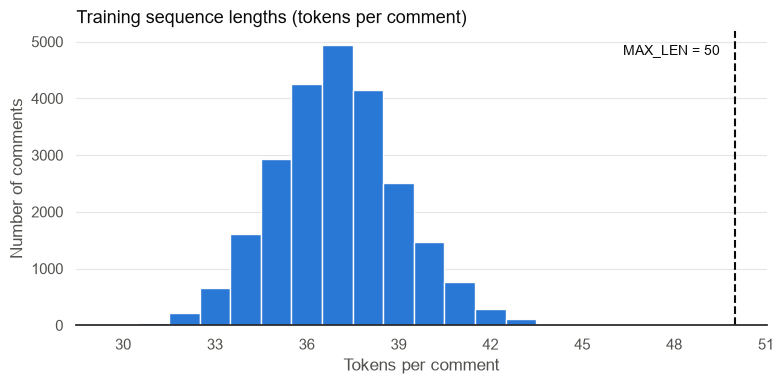

Saved to outputs/plots/sequence_length_distribution.png


In [40]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(train_lengths, bins=np.arange(train_lengths.min() - 0.5, train_lengths.max() + 1.5), color="#2a78d6", edgecolor="#fcfcfb", linewidth=1)
ax.axvline(MAX_LEN, color="#0b0b0b", linestyle="--", linewidth=1.5)
ax.text(MAX_LEN - 0.5, ax.get_ylim()[1] * 0.92, f"MAX_LEN = {MAX_LEN}", ha="right", color="#0b0b0b", fontsize=10)

ax.set_title("Training sequence lengths (tokens per comment)", loc="left", fontsize=13, color="#0b0b0b")
ax.set_xlabel("Tokens per comment", color="#52514e")
ax.set_ylabel("Number of comments", color="#52514e")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.tick_params(colors="#52514e")
ax.grid(axis="y", color="#e5e5e3", linewidth=0.8)
ax.set_axisbelow(True)
sns.despine(left=True)

plt.tight_layout()
fig.savefig(PLOTS_DIR / "sequence_length_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved to outputs/plots/sequence_length_distribution.png")

### 3.7 Pad and truncate the sequences

`pad_sequences()` makes every sequence exactly `MAX_LEN` long:

- **Padding** adds zeros to short sequences. We use `padding="pre"` (zeros at the **start**), so the
  real words sit at the end, right before the LSTM produces its output. Index 0 is reserved for
  padding and never used for a real word.
- **Truncation** cuts sequences longer than `MAX_LEN`. We use `truncating="post"` (cut from the
  **end**), so the start of a comment is kept. With our `MAX_LEN`, no training sequence is
  truncated; this setting protects against unusually long new comments.

In [41]:
PADDING = "pre"
TRUNCATING = "post"

X_train = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding=PADDING, truncating=TRUNCATING)
X_test = pad_sequences(X_test_seq, maxlen=MAX_LEN, padding=PADDING, truncating=TRUNCATING)

print("Original sequence (length", len(X_train_seq[0]), "):")
print(X_train_seq[0])
print()
print("Padded sequence (length", len(X_train[0]), "):")
print(X_train[0])

Original sequence (length 39 ):
[5, 2, 61, 137, 70, 2, 21, 78, 8, 26, 15, 2, 38, 69, 151, 9, 6, 3, 5, 7, 10, 14, 66, 184, 185, 181, 4, 11, 23, 186, 30, 2, 6, 4, 27, 103, 104, 105, 61]

Padded sequence (length 50 ):
[  0   0   0   0   0   0   0   0   0   0   0   5   2  61 137  70   2  21
  78   8  26  15   2  38  69 151   9   6   3   5   7  10  14  66 184 185
 181   4  11  23 186  30   2   6   4  27 103 104 105  61]


In [42]:
print("Decoded back to words (padding shown as _):")
index_word = tokenizer.index_word
print(" ".join(index_word.get(i, "_") for i in X_train[0]))

Decoded back to words (padding shown as _):
_ _ _ _ _ _ _ _ _ _ _ for the matter being discussed the statement presents a perspective on the issue at hand source wording comment for review this message contains severe abusive language and should be removed so the wording and its intended target both matter


### 3.8 Final array shapes

These arrays are the inputs and targets for the model in Task 4:

- `X_train`, `X_test`: shape `(number_of_comments, MAX_LEN)`, integer word indices
- `y_train`, `y_test`: shape `(number_of_comments,)`, integer class labels

In [43]:
shapes = pd.DataFrame({
    "shape": [X_train.shape, X_test.shape, y_train.shape, y_test.shape],
    "dtype": [X_train.dtype, X_test.dtype, y_train.dtype, y_test.dtype],
}, index=["X_train", "X_test", "y_train", "y_test"])
shapes

,shape,dtype
X_train,"(24000, 50)",int32
X_test,"(6000, 50)",int32
y_train,"(24000,)",int64
y_test,"(6000,)",int64


In [44]:
print("Summary of Task 3 settings")
print(f"  Vocabulary size (VOCAB_SIZE): {VOCAB_SIZE:,}")
print(f"  Maximum sequence length     : {MAX_LEN}")
print(f"  Padding / truncating        : {PADDING} / {TRUNCATING}")
print(f"  Number of classes           : {NUM_CLASSES} -> {CLASS_NAMES}")

Summary of Task 3 settings
  Vocabulary size (VOCAB_SIZE): 212
  Maximum sequence length     : 50
  Padding / truncating        : pre / post
  Number of classes           : 5 -> ['Clean', 'Identity_Attack', 'Severe_Toxic', 'Threat', 'Toxic']


### Task 3 Summary

- The data was split 80/20 with stratification, so every class has the same share in both sets.
- The class names were encoded as integers with `LabelEncoder` (fitted on the training labels).
- The tokenizer was fitted on the **training text only**; the test set was converted with it,
  exactly as new comments will be.
- All sequences were padded to the same length (`MAX_LEN`), chosen so no training comment is cut.

The tokenizer, label encoder, and settings will be saved together with the trained model (Task 4),
because the prediction script needs exactly the same preprocessing.

Next, Task 4 builds the LSTM model.

---
## Task 4: Deep Learning Model Development, Training, and Validation

In this task we build a **Long Short-Term Memory (LSTM)** neural network that reads a padded
sequence of word indices and outputs one probability per toxicity class. This first part builds and
compiles the model; the next part trains and validates it.

### 4.1 Model hyperparameters

All settings are defined in one place so they are easy to read and change.

| Setting | Value | Why |
|---|---|---|
| `EMBEDDING_DIM` | 64 | Each word becomes a vector of 64 numbers. The vocabulary is small (212), so a modest size is enough. |
| `LSTM_UNITS` | 64 | Size of the LSTM's memory. |
| `DENSE_UNITS` | 32 | Hidden fully connected layer between the LSTM and the output. |
| `DROPOUT_RATE` | 0.3 | 30% of the values are randomly switched off during training to reduce overfitting. |
| `LEARNING_RATE` | 0.001 | The standard default learning rate for the Adam optimizer. |

In [45]:
from tensorflow import keras
from tensorflow.keras import layers

EMBEDDING_DIM = 64
LSTM_UNITS = 64
DENSE_UNITS = 32
DROPOUT_RATE = 0.3
LEARNING_RATE = 0.001

print(f"Input length (MAX_LEN): {MAX_LEN}")
print(f"Vocabulary size       : {VOCAB_SIZE}")
print(f"Output classes        : {NUM_CLASSES}")
print("Keras version:", keras.__version__)

Input length (MAX_LEN): 50
Vocabulary size       : 212
Output classes        : 5
Keras version: 3.15.1


### 4.2 Build the LSTM model

The model is a `Sequential` stack: data flows through the layers from top to bottom.

| Layer | Output shape | Role |
|---|---|---|
| **Input** | (50,) | Receives one padded sequence of 50 word indices. |
| **Embedding** | (50, 64) | Turns every word index into a learned 64-number vector. Words used in similar ways end up with similar vectors. |
| **LSTM** | (64,) | Reads the word vectors **in order**, one at a time, keeping a memory of what came before. Its final memory state summarises the whole comment. Because padding is at the start, the real words are the last ones it reads. |
| **Dropout** | (64,) | During training, randomly sets 30% of the LSTM outputs to zero, so the model cannot rely on a few specific values (reduces overfitting). Dropout is switched off automatically at prediction time. |
| **Dense (ReLU)** | (32,) | A fully connected layer that combines the LSTM features into higher-level patterns. ReLU keeps positive values and sets negatives to zero. |
| **Dropout** | (32,) | Second dropout layer for extra regularisation. |
| **Dense (Softmax)** | (5,) | Output layer with one unit per class. **Softmax** turns the 5 raw scores into probabilities that add up to 1; the class with the highest probability is the prediction. |

In [46]:
keras.utils.set_random_seed(RANDOM_STATE)

model = keras.Sequential(
    [
        layers.Input(shape=(MAX_LEN,), name="input_sequence"),
        layers.Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM, name="embedding"),
        layers.LSTM(LSTM_UNITS, name="lstm"),
        layers.Dropout(DROPOUT_RATE, name="dropout_1"),
        layers.Dense(DENSE_UNITS, activation="relu", name="dense_relu"),
        layers.Dropout(DROPOUT_RATE, name="dropout_2"),
        layers.Dense(NUM_CLASSES, activation="softmax", name="output_softmax"),
    ],
    name="toxic_comment_lstm",
)

### 4.3 Compile the model

Compiling tells Keras **how** the model will learn:

- **Optimizer: Adam.** Adjusts the weights after each batch, adapting the step size for every
  weight automatically. It is a reliable default for LSTMs.
- **Loss: `sparse_categorical_crossentropy`.** Measures how far the predicted probabilities are
  from the true class. *Categorical* because there are several mutually exclusive classes;
  *sparse* because our labels are integers (0–4) rather than one-hot vectors. This matches the
  label format chosen in Task 3.
- **Metric: accuracy.** The share of comments whose highest-probability class is correct. It is
  easy to read during training; the full per-class evaluation comes in Task 5.

In [47]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
print("Model compiled: optimizer=Adam, loss=sparse_categorical_crossentropy, metrics=[accuracy]")

Model compiled: optimizer=Adam, loss=sparse_categorical_crossentropy, metrics=[accuracy]


### 4.4 Model summary

The summary lists every layer, its output shape, and its number of **trainable parameters**
(the weights the model learns):

- **Embedding:** `VOCAB_SIZE × EMBEDDING_DIM` = 212 × 64
- **LSTM:** `4 × (units × (input_dim + units) + units)`. The 4 comes from the LSTM's three gates
  (input, forget, output) plus its candidate memory.
- **Dense:** `inputs × units + units` (weights plus biases)
- **Dropout:** no parameters; it only switches values off during training.

The summary is also saved to `outputs/reports/model_summary.txt`.

In [48]:
model.summary()

Model: "toxic_comment_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 50, 64)         │        13,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_relu (Dense)              │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_softmax (Dense)          │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 48,837 (190.77 KB)

 Trainable params: 48,837 (190.77 KB)

 Non-trainable params: 0 (0.00 B)

In [49]:
summary_lines = []
model.summary(print_fn=lambda line, **kwargs: summary_lines.append(line))
(REPORTS_DIR / "model_summary.txt").write_text("\n".join(summary_lines), encoding="utf-8")

expected = {
    "embedding": VOCAB_SIZE * EMBEDDING_DIM,
    "lstm": 4 * (LSTM_UNITS * (EMBEDDING_DIM + LSTM_UNITS) + LSTM_UNITS),
    "dense_relu": LSTM_UNITS * DENSE_UNITS + DENSE_UNITS,
    "output_softmax": DENSE_UNITS * NUM_CLASSES + NUM_CLASSES,
}
param_check = pd.DataFrame({
    "parameters (Keras)": [model.get_layer(name).count_params() for name in expected],
    "parameters (formula)": list(expected.values()),
}, index=list(expected))
print("Summary saved to outputs/reports/model_summary.txt")
print(f"Total parameters: {model.count_params():,}")
param_check

Summary saved to outputs/reports/model_summary.txt
Total parameters: 48,837


,parameters (Keras),parameters (formula)
embedding,13568,13568
lstm,33024,33024
dense_relu,2080,2080
output_softmax,165,165


### 4.5 Sanity check before training

Before training, we pass two training sequences through the **untrained** model. This only checks
that the input and output shapes are correct and that the Softmax probabilities add up to 1. The
predictions are meaningless at this point (the weights are still random), so they should be close
to 1/5 = 0.2 for every class.

In [50]:
sample_probs = model.predict(X_train[:2], verbose=0)
print("Output shape:", sample_probs.shape, "(2 comments x", NUM_CLASSES, "classes)")
print("Sum of probabilities per comment:", sample_probs.sum(axis=1).round(4))
pd.DataFrame(sample_probs.round(4), columns=CLASS_NAMES, index=["sample 1", "sample 2"])

Output shape: (2, 5) (2 comments x 5 classes)
Sum of probabilities per comment: [1. 1.]


,Clean,Identity_Attack,Severe_Toxic,Threat,Toxic
sample 1,0.1998,0.2003,0.2000,0.1997,0.2001
sample 2,0.1983,0.2000,0.2003,0.2002,0.2012


### Model development summary

- The LSTM model (Embedding → LSTM → Dropout → Dense → Dropout → Dense with Softmax) is built and
  compiled with Adam and `sparse_categorical_crossentropy`, matching the integer labels.
- The parameter counts match the formulas, and the untrained model produces valid probability
  outputs of the right shape.

Next, the model is trained with a validation split taken from the training set. The test set is
still untouched.

### 4.6 Create a validation set from the training data

During training we need to check how well the model handles comments it has **not** learned from,
without touching the test set. So we hold back **10% of the training set** as a **validation set**:

- **Training part (90%)**: the model learns its weights from these comments.
- **Validation part (10%)**: checked after every epoch to watch for overfitting and to decide when
  to stop training.
- **Test set**: still untouched; it is used only once, in Task 5.

Keras's `validation_split` argument would simply take the **last** 10% of the rows without
stratifying. Instead we use `train_test_split` with `stratify`, so the small classes are fairly
represented in the validation set too.

In [51]:
# Row positions are split too, so each validation sequence can be traced back to its original text
X_tr, X_val, y_tr, y_val, idx_tr, idx_val = train_test_split(
    X_train, y_train, np.arange(len(X_train)),
    test_size=0.10,
    stratify=y_train,
    random_state=RANDOM_STATE,
)

print(f"Training part  : {X_tr.shape[0]:,} comments")
print(f"Validation part: {X_val.shape[0]:,} comments")
print(f"Test set       : {X_test.shape[0]:,} comments (not used during training)")

pd.DataFrame({
    "train part %": (pd.Series(y_tr).value_counts(normalize=True).sort_index() * 100).round(2).values,
    "validation part %": (pd.Series(y_val).value_counts(normalize=True).sort_index() * 100).round(2).values,
}, index=CLASS_NAMES)

Training part  : 21,600 comments
Validation part: 2,400 comments
Test set       : 6,000 comments (not used during training)


,train part %,validation part %
Clean,61.93,61.92
Identity_Attack,4.89,4.92
Severe_Toxic,6.00,6.00
Threat,4.86,4.88
Toxic,22.31,22.29


### 4.7 Training settings and EarlyStopping

| Setting | Value | Why |
|---|---|---|
| `EPOCHS` | 12 | One epoch = one full pass over the training data. 12 is within the required 10–20 range. |
| `BATCH_SIZE` | 64 | The weights are updated after every 64 comments, a common balance between speed and stable learning. |
| `EarlyStopping` | monitor `val_loss`, patience 3 | If the validation loss does not improve for 3 epochs in a row, training stops early. |
| `restore_best_weights` | True | After stopping, the model goes back to the weights from the epoch with the **lowest validation loss**. |

EarlyStopping protects against **overfitting**, where the model keeps improving on the training data
but gets worse on unseen data.

In [52]:
EPOCHS = 12
BATCH_SIZE = 64

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1,
)

### 4.8 Train the model

`model.fit()` trains the model. After each epoch Keras reports four values:

- `loss` / `accuracy`: on the training part (with dropout active)
- `val_loss` / `val_accuracy`: on the validation part (dropout switched off)

The training time is measured as well.

In [53]:
import time

keras.utils.set_random_seed(RANDOM_STATE)
start_time = time.time()

history = model.fit(
    X_tr, y_tr,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping],
    verbose=2,
)

training_seconds = time.time() - start_time
print(f"\nTraining finished in {training_seconds:.1f} seconds")

Epoch 1/12


338/338 - 9s - 28ms/step - accuracy: 0.8528 - loss: 0.3864 - val_accuracy: 0.9983 - val_loss: 0.0620


Epoch 2/12


338/338 - 10s - 30ms/step - accuracy: 0.9963 - loss: 0.0186 - val_accuracy: 1.0000 - val_loss: 4.5572e-04


Epoch 3/12


...

Epoch 12/12


338/338 - 11s - 33ms/step - accuracy: 0.9998 - loss: 0.0024 - val_accuracy: 1.0000 - val_loss: 3.9536e-05


Epoch 12: early stopping


Restoring model weights from the end of the best epoch: 9.



Training finished in 119.4 seconds


### 4.9 Training history

The `history` object records the loss and accuracy after every epoch. We show it as a table and
save it to `outputs/reports/training_history.csv`, so the accuracy and loss curves in Task 5 can be
plotted from the real values.

In [54]:
history_df = pd.DataFrame(history.history)
history_df.index = range(1, len(history_df) + 1)
history_df.index.name = "epoch"
history_df.to_csv(REPORTS_DIR / "training_history.csv")

epochs_run = len(history_df)
best_epoch = int(history_df["val_loss"].idxmin())

print(f"Epochs run : {epochs_run} of {EPOCHS}")
print(f"Best epoch : {best_epoch} (lowest val_loss; these weights are kept)")
print(f"Best val_loss    : {history_df.loc[best_epoch, 'val_loss']:.2e}")
print(f"Best val_accuracy: {history_df.loc[best_epoch, 'val_accuracy']:.4f}")
print("Saved to outputs/reports/training_history.csv")

# Loss values become very small, so they are shown in scientific notation (e.g. 1.36e-08)
history_display = history_df.copy()
for col in ["accuracy", "val_accuracy"]:
    history_display[col] = history_df[col].map("{:.4f}".format)
for col in ["loss", "val_loss"]:
    history_display[col] = history_df[col].map("{:.2e}".format)
history_display

Epochs run : 12 of 12
Best epoch : 9 (lowest val_loss; these weights are kept)
Best val_loss    : 1.36e-08
Best val_accuracy: 1.0000
Saved to outputs/reports/training_history.csv


,accuracy,loss,val_accuracy,val_loss
epoch,,,,
1,0.8528,3.86e-01,0.9983,6.20e-02
2,0.9963,1.86e-02,1.0000,4.56e-04
3,0.9989,5.48e-03,1.0000,2.09e-05
4,0.9994,2.83e-03,1.0000,3.20e-06
5,0.9997,1.84e-03,1.0000,1.80e-06
6,0.9996,1.55e-03,1.0000,2.80e-07
7,0.9997,1.16e-03,1.0000,1.12e-07
8,0.9998,9.04e-04,1.0000,3.87e-08
9,0.9999,5.89e-04,1.0000,1.36e-08


**Interpreting the training run**

- The training and validation accuracy rise to almost 100% within the first few epochs, and the
  validation loss falls close to zero. The exact values are in the table above.
- An occasional jump in the training loss for a single epoch can happen with the Adam optimizer
  when the loss is already tiny. EarlyStopping restores the weights from the epoch with the
  lowest validation loss, so such an epoch does not affect the saved model.
- **Why is it this easy?** As found in Task 2, the dataset is built from only 17 core comments,
  so the validation comments contain the same core sentences as the training comments (with
  different surrounding phrases). The model only needs to recognise which core sentence is
  present. This near-perfect score is a property of this dataset, not proof that the model
  understands toxicity in general. Task 5 checks this with genuinely new comments.

### 4.10 Save the trained model and the preprocessing artifacts

To classify new comments later (in `src/predict.py`) we need **exactly the same preprocessing**
used during training, not just the model. We save everything into `models/`:

| File | Contents |
|---|---|
| `toxic_lstm_model.keras` | The trained model (architecture + weights + optimizer state), in the native Keras format |
| `tokenizer.json` | The fitted tokenizer (vocabulary and word indices) |
| `label_classes.json` | The class names in encoder order (index 0 → `Clean`, ...) |
| `preprocessing_config.json` | `MAX_LEN`, padding, truncating, vocabulary size, and other settings |

The tokenizer and class list are saved as **JSON** text files rather than pickle files: JSON is
readable and does not run code when loaded. The `models/` folder is excluded from Git by
`.gitignore`, because model files can be large; re-running the notebook recreates them.

In [55]:
import json

MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODELS_DIR / "toxic_lstm_model.keras"
TOKENIZER_PATH = MODELS_DIR / "tokenizer.json"
LABELS_PATH = MODELS_DIR / "label_classes.json"
CONFIG_PATH = MODELS_DIR / "preprocessing_config.json"

model.save(MODEL_PATH)
TOKENIZER_PATH.write_text(tokenizer.to_json(), encoding="utf-8")
LABELS_PATH.write_text(json.dumps(CLASS_NAMES, indent=2), encoding="utf-8")

preprocessing_config = {
    "max_len": MAX_LEN,
    "padding": PADDING,
    "truncating": TRUNCATING,
    "vocab_size": VOCAB_SIZE,
    "max_words": MAX_WORDS,
    "oov_token": OOV_TOKEN,
    "num_classes": NUM_CLASSES,
    "text_cleaning": "src.preprocessing.clean_text",
}
CONFIG_PATH.write_text(json.dumps(preprocessing_config, indent=2), encoding="utf-8")

for p in [MODEL_PATH, TOKENIZER_PATH, LABELS_PATH, CONFIG_PATH]:
    print(f"Saved {p.relative_to(PROJECT_ROOT)} ({p.stat().st_size / 1024:.1f} KB)")

Saved models\toxic_lstm_model.keras (608.6 KB)
Saved models\tokenizer.json (18.9 KB)
Saved models\label_classes.json (0.1 KB)
Saved models\preprocessing_config.json (0.2 KB)


### 4.11 Verify that the saved artifacts load correctly

We load every saved file back and check that it gives **identical results** to the objects in
memory. The check uses validation comments, so the test set stays unused.

In [56]:
from tf_keras.preprocessing.text import tokenizer_from_json

loaded_model = keras.models.load_model(MODEL_PATH)
loaded_tokenizer = tokenizer_from_json(TOKENIZER_PATH.read_text(encoding="utf-8"))
loaded_classes = json.loads(LABELS_PATH.read_text(encoding="utf-8"))
loaded_config = json.loads(CONFIG_PATH.read_text(encoding="utf-8"))

# 1. Model: same predictions as the in-memory model
probs_memory = model.predict(X_val[:100], verbose=0)
probs_loaded = loaded_model.predict(X_val[:100], verbose=0)
print("Model predictions identical      :", np.allclose(probs_memory, probs_loaded, atol=1e-6))

# 2. Tokenizer: same sequences as the in-memory tokenizer
sample_texts = list(X_train_text.iloc[:100])
print("Tokenizer sequences identical    :", tokenizer.texts_to_sequences(sample_texts) == loaded_tokenizer.texts_to_sequences(sample_texts))

# 3. Class names and settings
print("Class names identical            :", loaded_classes == CLASS_NAMES)
print("Config matches notebook settings :", loaded_config["max_len"] == MAX_LEN and loaded_config["padding"] == PADDING)

Model predictions identical      : True
Tokenizer sequences identical    : True
Class names identical            : True
Config matches notebook settings : True


### 4.12 End-to-end check with the saved artifacts

As a final check, we run one **raw** validation comment through the full pipeline using only the
loaded files (raw text → `clean_text` → tokenizer → padding → model) and compare it with its true
label. The full evaluation on the test set happens in Task 5.

In [57]:
val_raw_index = X_train_text.index[idx_val[0]]  # original row of the first validation comment
raw_comment = df.loc[val_raw_index, "Comment_Text"]
true_label = df.loc[val_raw_index, "Toxicity_Label"]

seq = loaded_tokenizer.texts_to_sequences([clean_text(raw_comment)])
padded = pad_sequences(seq, maxlen=loaded_config["max_len"],
                       padding=loaded_config["padding"], truncating=loaded_config["truncating"])
probs = loaded_model.predict(padded, verbose=0)[0]

print("Raw comment:", raw_comment)
print("True label :", true_label)
print("Predicted  :", loaded_classes[int(probs.argmax())], f"(confidence {probs.max():.4f})")

Raw comment:

 On this subject, the message expresses a statement whose intent depends on context. Source wording: Comment for review: "That response is aggressive and not helpful.". while readers consider whether the wording is constructive or harmful.
True label : Toxic
Predicted  : Toxic (confidence 1.0000)


### Task 4 Summary

- The model was trained on 90% of the training set and validated on the other 10% after every epoch,
  with EarlyStopping watching the validation loss.
- The epoch-by-epoch history (shown above) is saved to `outputs/reports/training_history.csv`.
- The trained model, tokenizer, class names, and preprocessing settings are saved in `models/`, and
  reloading them gives identical results.
- The test set has still not been used. Task 5 evaluates the model on it.